# 105 ModalFormer (src8): new architectures vs `s7-gpc-tukey-logpower-1k`

**Goal:** match or beat the target on **IoU and miss at threshold 0.08**.
- **CORE**: the four base objects (vase, cube, soap dispenser, candle) × 3 boxes, 12 splits.
- **HARD**: the cardboard rotated soap dispenser, scored with orientation error.

ALL (54 non-control splits) is secondary.

Scoring: `src8/score.py` (pred > 0.08 vs true > 0.5). Each split is a mean over its samples, then a mean over splits.
- Code: `src8/` (arch.py ModalFormer, run.py, score.py, probe.py, fitdiag.py, signal_probe.py)
- Runs: `scripts/modal_src8_v2.sh` (500 ep)
- Write-up of everything tried: `src8/EXPERIMENTS.md`

Sections:
1. Headline
2. CORE by object × box
3. Learning curves
4. The hard case: rotated soap
5. Generalization
6. What the models read (input perturbations)
7. Signal quality without training
8. Interpretability

In [1]:
import sys, json, glob, math
from pathlib import Path
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src8"))
from score import per_sample, summarize, truth
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40)

TARGET = "s7-gpc-tukey-logpower-1k"
def epochs(run): return sorted({int(p.name[2:6]) for p in (ROOT / "runs" / run / "outputs_history/eval").rglob("ep*.pt")})
RUNS = [TARGET, "s7-gpc-tukey-base-1k"] + sorted(p.name for p in (ROOT / "runs").glob("s8-*-500ep") if (p / "outputs_history/eval").exists() and max(epochs(p.name), default=0) >= 100)
T = 0.08
COLS = [f"iou@{T}", f"miss@{T}", f"orient_err@{T}", f"biou@{T}", f"area_ratio@{T}", f"phantom@{T}", "iou_auc", f"spk_consistency@{T}"]
def summary(run, ep): s, sp = summarize(per_sample(run, ep, [T]), COLS); return s, sp
print({r: max(epochs(r)) for r in RUNS})

/home/ethantu/workspace/good-vibrations/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:1061: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()


{'s7-gpc-tukey-logpower-1k': 750, 's7-gpc-tukey-base-1k': 1000, 's8-best-jitter-500ep': 500, 's8-best-spkgain-500ep': 500, 's8-best-tversky-500ep': 500, 's8-conv-logpower-500ep': 500, 's8-hybrid-base-500ep': 500, 's8-hybrid-pose-500ep': 500, 's8-hybrid-posesum-500ep': 500, 's8-posesum-contour-500ep': 500}


## 1 Headline

Each s8 run at its last epoch and at ep500. The target at ep500 (the same point in a 500-ep run's budget; its ep750 score is 0.299 vs 0.300 at ep500). Δ = run − target.

In [2]:
rows = []
for r in RUNS:
    ep = 500 if r.startswith("s7") else max(epochs(r))
    s, _ = summary(r, ep)
    rows.append({"run": r, "epoch": ep} | {f"{g} {k.split('@')[0]}": s.loc[g, k] for g in ("CORE", "HARD", "ALL") for k in (f"iou@{T}", f"miss@{T}", f"orient_err@{T}")})
head = pd.DataFrame(rows).set_index("run")
tgt = head.loc[TARGET]
delta = head.drop(columns="epoch") - tgt.drop("epoch")
display(head.round(3)); display(delta.round(3).add_prefix("Δ "))

,epoch,CORE iou,CORE miss,CORE orient_err,HARD iou,HARD miss,HARD orient_err,ALL iou,ALL miss,ALL orient_err
run,,,,,,,,,,
s7-gpc-tukey-logpower-1k,500,0.580,0.043,15.506,0.420,0.024,36.345,0.300,0.272,27.687
s7-gpc-tukey-base-1k,500,0.621,0.030,12.959,0.431,0.048,32.155,0.326,0.244,26.028
s8-best-jitter-500ep,500,0.705,0.009,4.079,0.603,0.000,16.052,0.367,0.220,21.018
s8-best-spkgain-500ep,500,0.722,0.006,3.843,0.596,0.000,18.347,0.388,0.168,18.902
s8-best-tversky-500ep,500,0.698,0.012,4.660,0.579,0.016,18.705,0.359,0.197,22.244
s8-conv-logpower-500ep,500,0.577,0.046,14.296,0.408,0.032,36.414,0.299,0.266,28.214
s8-hybrid-base-500ep,500,0.643,0.029,12.820,0.518,0.016,30.215,0.336,0.252,27.072
s8-hybrid-pose-500ep,500,0.570,0.012,15.983,0.454,0.000,28.995,0.294,0.199,26.874
s8-hybrid-posesum-500ep,500,0.662,0.025,9.307,0.550,0.008,21.265,0.342,0.255,22.160


,Δ CORE iou,Δ CORE miss,Δ CORE orient_err,Δ HARD iou,Δ HARD miss,Δ HARD orient_err,Δ ALL iou,Δ ALL miss,Δ ALL orient_err
run,,,,,,,,,
s7-gpc-tukey-logpower-1k,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
s7-gpc-tukey-base-1k,0.042,-0.012,-2.547,0.010,0.024,-4.190,0.026,-0.027,-1.659
s8-best-jitter-500ep,0.125,-0.034,-11.427,0.182,-0.024,-20.293,0.067,-0.052,-6.669
s8-best-spkgain-500ep,0.142,-0.037,-11.663,0.176,-0.024,-17.999,0.088,-0.104,-8.785
s8-best-tversky-500ep,0.118,-0.031,-10.846,0.159,-0.008,-17.641,0.059,-0.075,-5.443
s8-conv-logpower-500ep,-0.003,0.003,-1.210,-0.012,0.008,0.069,-0.001,-0.005,0.527
s8-hybrid-base-500ep,0.063,-0.013,-2.686,0.098,-0.008,-6.131,0.036,-0.020,-0.615
s8-hybrid-pose-500ep,-0.009,-0.031,0.478,0.034,-0.024,-7.350,-0.006,-0.073,-0.813
s8-hybrid-posesum-500ep,0.082,-0.018,-6.199,0.130,-0.016,-15.081,0.042,-0.016,-5.527


## 2 CORE: IoU and miss per object × box

In [3]:
core = ["candle", "cube", "soap-dispenser", "vase"]
tabs = {}
for r in RUNS:
    ep = 500 if r.startswith("s7") else max(epochs(r))
    _, sp = summary(r, ep)
    tabs[r] = sp[sp.split.isin(core)].set_index(["box", "split"])[[f"iou@{T}", f"miss@{T}"]]
iou = pd.concat({r: t[f"iou@{T}"] for r, t in tabs.items()}, axis=1)
miss = pd.concat({r: t[f"miss@{T}"] for r, t in tabs.items()}, axis=1)
print("iou@0.08"); display(iou.round(3).style.background_gradient(axis=1, cmap="RdYlGn"))
print("miss@0.08"); display(miss.round(3).style.background_gradient(axis=1, cmap="RdYlGn_r"))

iou@0.08


miss@0.08


## 3 Learning curves (CORE / HARD / ALL iou@0.08 and CORE miss vs epoch)

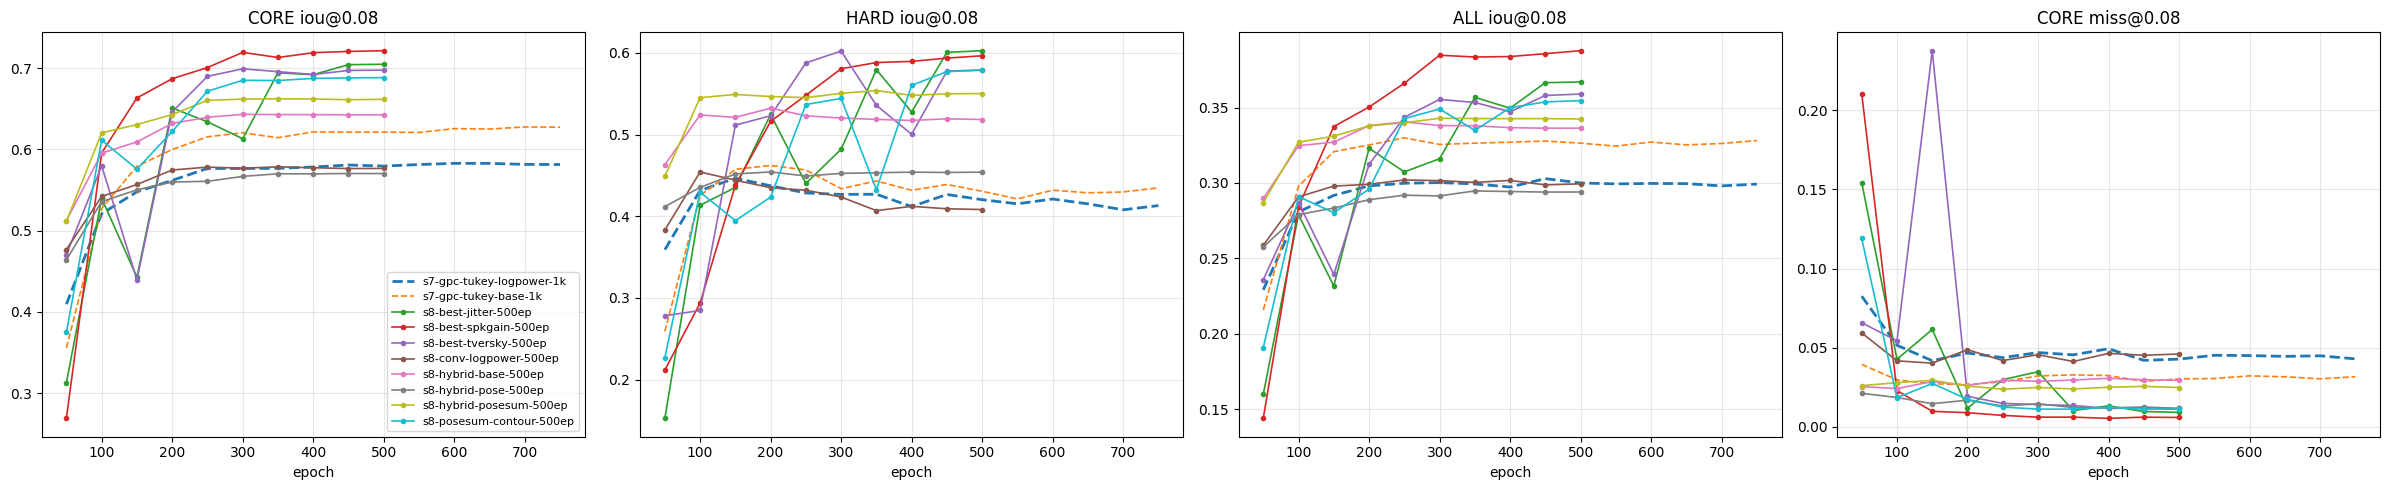

In [4]:
fig, axs = plt.subplots(1, 4, figsize=(24, 5))
for r in RUNS:
    eps = [e for e in epochs(r) if e % 50 == 0 and e > 0 and e <= (750 if r.startswith("s7") else 500)]
    ss = [summary(r, e)[0] for e in eps]
    for ax, (g, k) in zip(axs, [("CORE", f"iou@{T}"), ("HARD", f"iou@{T}"), ("ALL", f"iou@{T}"), ("CORE", f"miss@{T}")]):
        ax.plot(eps, [s.loc[g, k] for s in ss], "-o" if r.startswith("s8") else "--", label=r, lw=2 if r == TARGET else 1.2, ms=3)
        ax.set_title(f"{g} {k}"); ax.set_xlabel("epoch"); ax.grid(alpha=.3)
axs[0].legend(fontsize=8); plt.tight_layout(); plt.show()

## 4 The hard case: cardboard rotated soap dispenser

Orientation error is the angle between the principal axes of the predicted mask (> 0.08) and the true mask (elongated objects only; chance ≈ 45°).

Reference: a **linear ridge probe on the raw spectrum reads it at 16.9°** (EXPERIMENTS.md §2). The target model gets 36.5°.

Below: the scores per run, then predictions for the same 8 held-out samples.

,n,iou,miss,orient_err,biou,area_ratio
run,,,,,,
s7-gpc-tukey-logpower-1k,124,0.420,0.024,36.345,0.231,0.954
s7-gpc-tukey-base-1k,124,0.431,0.048,32.155,0.240,1.020
s8-best-jitter-500ep,124,0.603,0.000,16.052,0.310,1.250
s8-best-spkgain-500ep,124,0.596,0.000,18.347,0.323,1.227
s8-best-tversky-500ep,124,0.579,0.016,18.705,0.319,1.140
s8-conv-logpower-500ep,124,0.408,0.032,36.414,0.229,0.895
s8-hybrid-base-500ep,124,0.518,0.016,30.215,0.289,1.097
s8-hybrid-pose-500ep,124,0.454,0.000,28.995,0.214,1.622
s8-hybrid-posesum-500ep,124,0.550,0.008,21.265,0.314,1.079


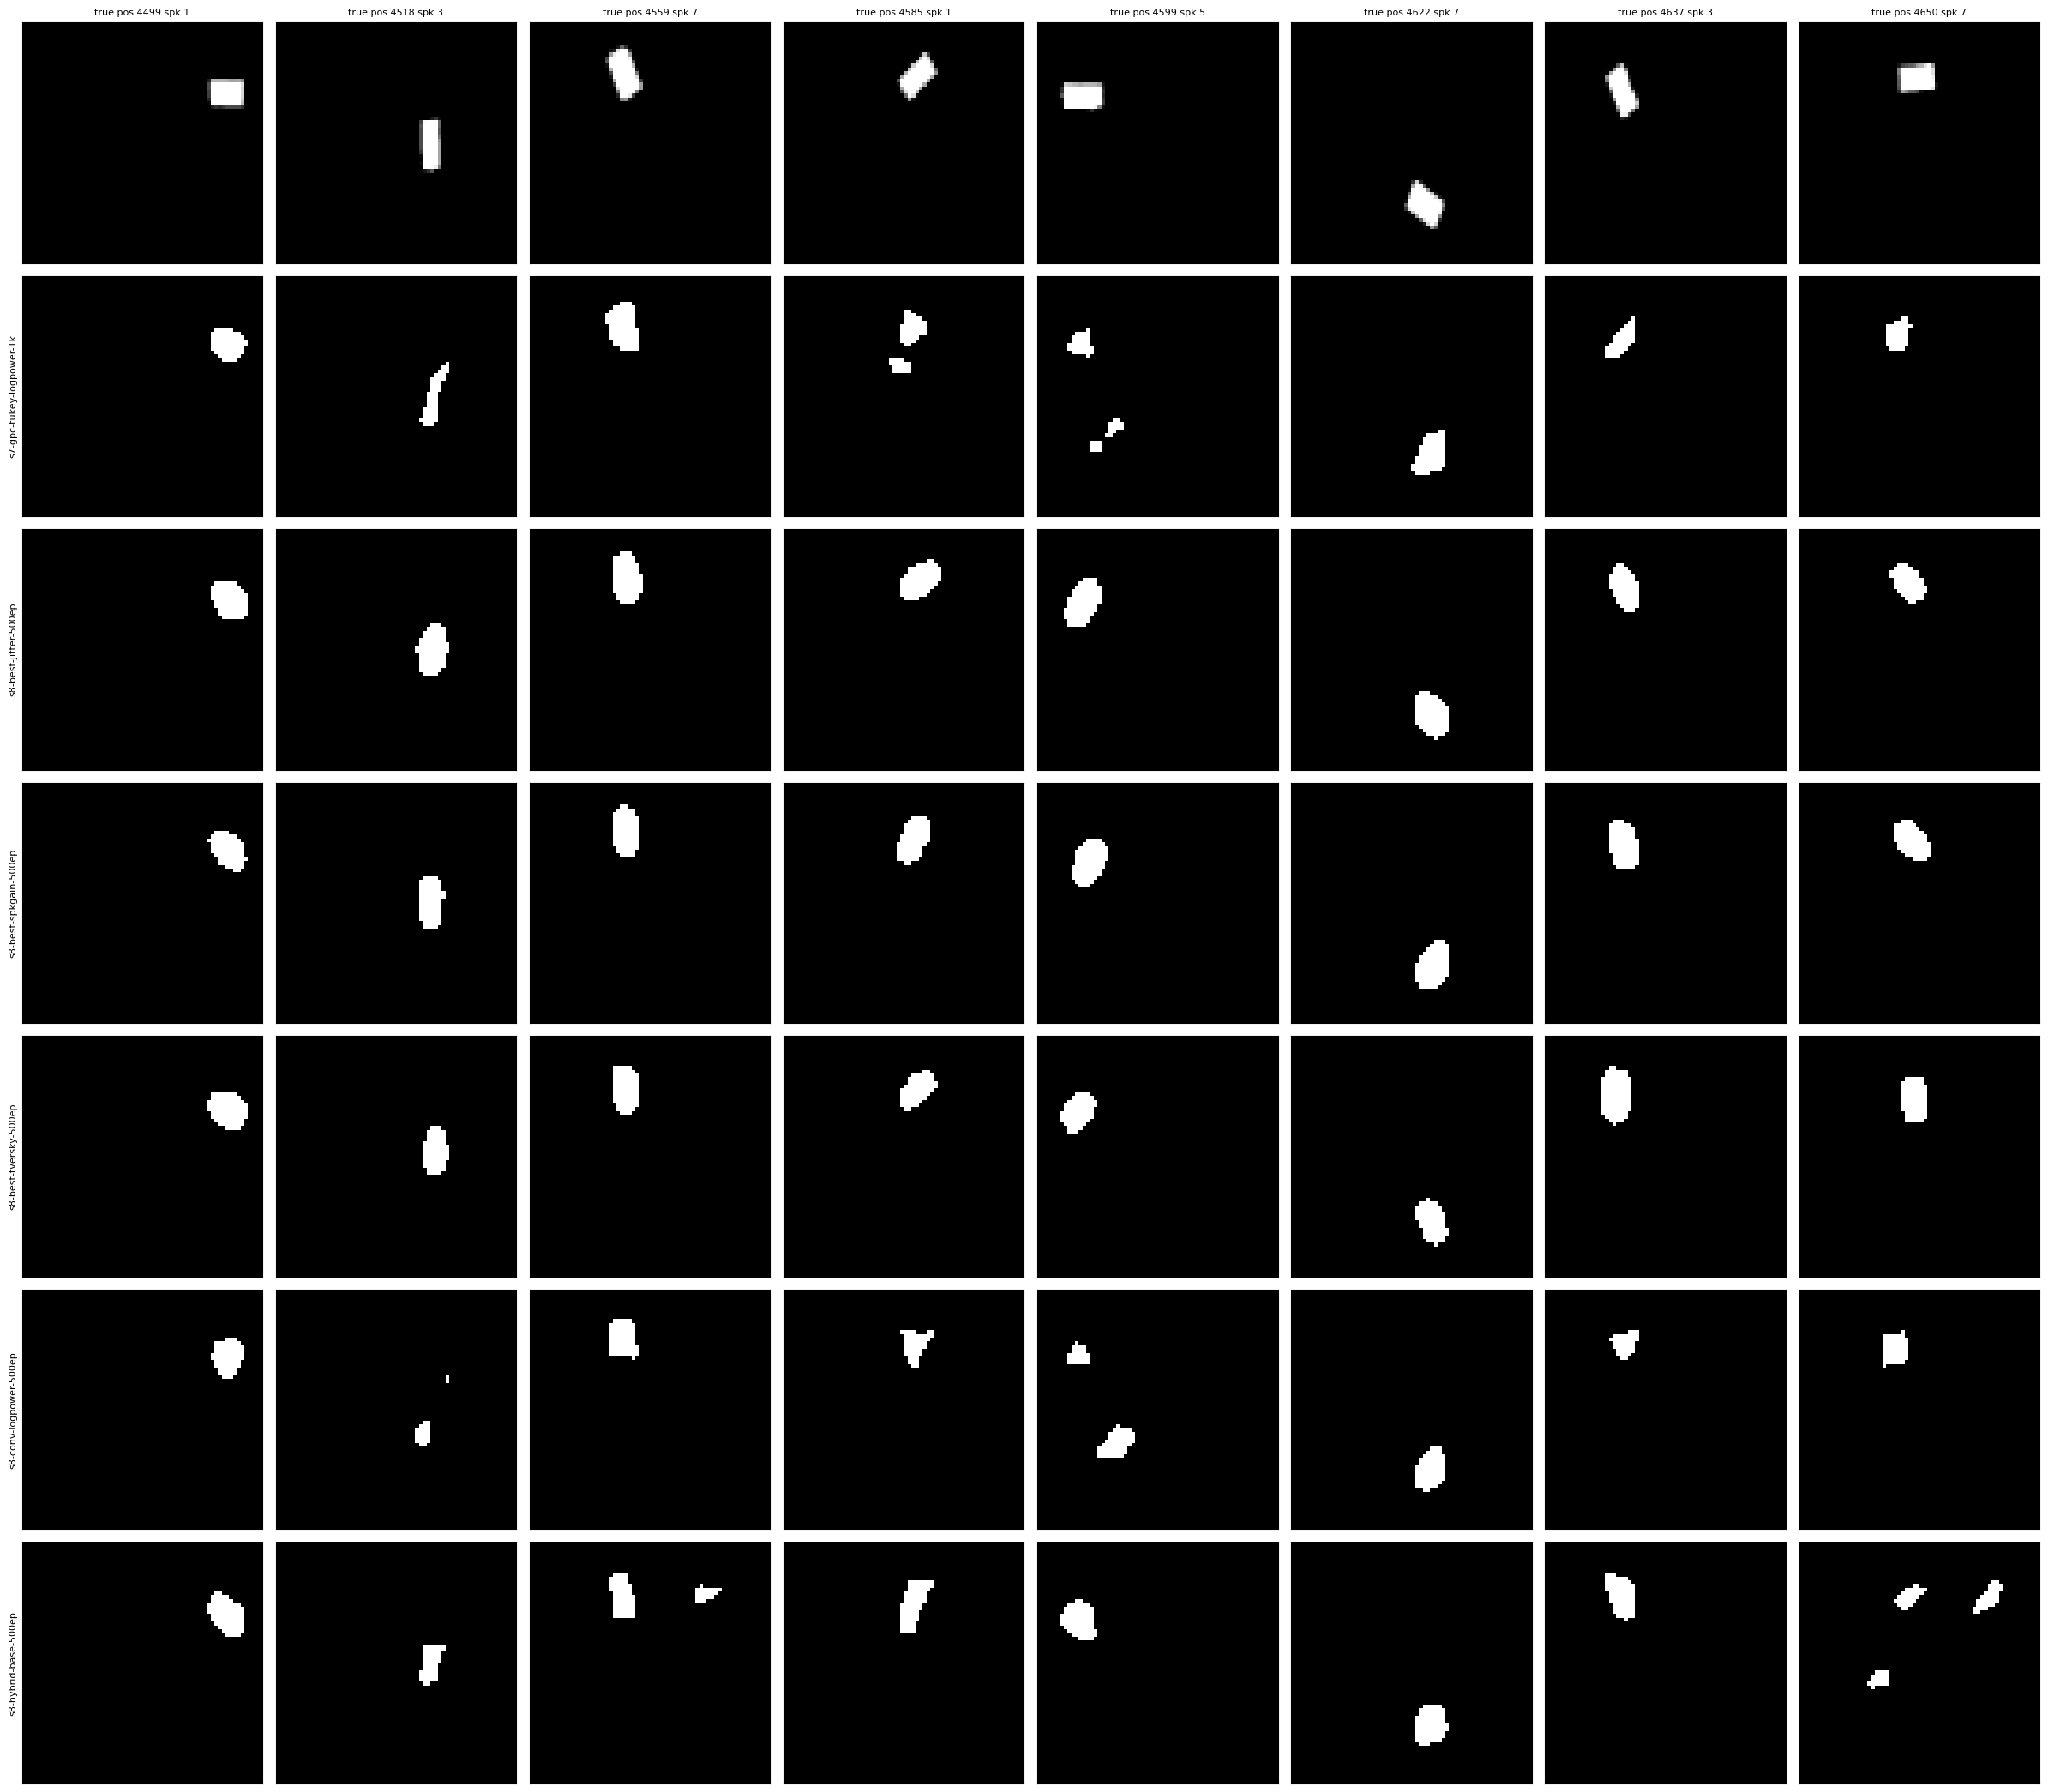

In [5]:
hard = []
for r in RUNS:
    ep = 500 if r.startswith("s7") else max(epochs(r))
    d = per_sample(r, ep, [T]); d = d[(d.box == "cardboard") & (d.split == "soap-dispenser-rotated")]
    hard.append(dict(run=r, n=len(d), iou=d[f"iou@{T}"].mean(), miss=d[f"miss@{T}"].mean(), orient_err=d[f"orient_err@{T}"].mean(), biou=d[f"biou@{T}"].mean(),
                     area_ratio=d[f"area_ratio@{T}"].median()))
display(pd.DataFrame(hard).set_index("run").round(3))

def preds(run, ep, split="cardboard/soap-dispenser-rotated"):
    P, I = [], []
    for f in sorted((ROOT / "runs" / run / "outputs_history/eval" / split).glob(f"ep{ep:04d}-*.pt")):
        d = torch.load(f, weights_only=False); P.append(d["mask_pred"].float()); I += list(zip(d["info"]["experiment"], d["info"]["sample_id"], d["info"]["position_id"].tolist(), d["info"]["speaker"].tolist()))
    return torch.cat(P).numpy(), I
show = [r for r in RUNS if r != "s7-gpc-tukey-base-1k"][:6]
P0, I0 = preds(TARGET, 500)
pick = np.linspace(0, len(I0) - 1, 8).astype(int)
fig, axs = plt.subplots(len(show) + 1, 8, figsize=(24, 3 * (len(show) + 1)))
for j, k in enumerate(pick):
    axs[0, j].imshow(truth(*I0[k], 64, 64), cmap="gray"); axs[0, j].set_title(f"true pos {I0[k][2]} spk {I0[k][3]}", fontsize=8)
for i, r in enumerate(show):
    P, I = preds(r, 500 if r.startswith("s7") else max(epochs(r)))
    idx = {x: n for n, x in enumerate(I)}
    for j, k in enumerate(pick):
        axs[i + 1, j].imshow(P[idx[I0[k]]] > T, cmap="gray"); axs[i + 1, 0].set_ylabel(r, fontsize=8)
for a in axs.flat: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

## 5 Generalization: by category, and by distance to the nearest training position

The signal's spectral distance saturates beyond about 0.15 of the box (EXPERIMENTS.md §2). The second table shows how each model degrades with distance from the training positions.

In [6]:
cat = {}
dist = {}
bins = [0, .05, .1, .15, .2, .3, 1.5]
for r in RUNS:
    ep = 500 if r.startswith("s7") else max(epochs(r))
    s, sp = summary(r, ep)
    cat[r] = s.loc[[k for k in s.index if "/" in k and not k.endswith("/all")], f"iou@{T}"]
    d = per_sample(r, ep, [T])
    dist[r] = d.groupby(pd.cut(d.train_dist, bins))[f"iou@{T}"].mean()
display(pd.DataFrame(cat).round(3).style.background_gradient(axis=1, cmap="RdYlGn"))
display(pd.DataFrame(dist).round(3))

,s7-gpc-tukey-logpower-1k,s7-gpc-tukey-base-1k,s8-best-jitter-500ep,s8-best-spkgain-500ep,s8-best-tversky-500ep,s8-conv-logpower-500ep,s8-hybrid-base-500ep,s8-hybrid-pose-500ep,s8-hybrid-posesum-500ep,s8-posesum-contour-500ep
cardboard/broken,0.190000,0.185000,0.577000,0.495000,0.502000,0.214000,0.219000,0.337000,0.316000,0.474000
cardboard/control,0.387000,0.385000,0.530000,0.559000,0.453000,0.363000,0.401000,0.346000,0.448000,0.489000
cardboard/cylinder,0.036000,0.040000,0.126000,0.115000,0.100000,0.029000,0.045000,0.059000,0.051000,0.095000
cardboard/id,0.511000,0.545000,0.695000,0.710000,0.689000,0.509000,0.607000,0.547000,0.627000,0.682000
cardboard/lid,0.022000,0.021000,0.071000,0.104000,0.042000,0.029000,0.012000,0.036000,0.020000,0.037000
cardboard/multiple,0.241000,0.238000,0.279000,0.330000,0.386000,0.233000,0.316000,0.281000,0.306000,0.358000
cardboard/rotated,0.277000,0.325000,0.583000,0.521000,0.544000,0.305000,0.426000,0.413000,0.441000,0.515000
cardboard/unseen-laser,0.050000,0.086000,0.120000,0.162000,0.046000,0.046000,0.054000,0.041000,0.049000,0.055000
cardboard/unseen-object,0.451000,0.440000,0.528000,0.542000,0.485000,0.456000,0.485000,0.419000,0.492000,0.497000
cardboard/unseen-rotated-object,0.223000,0.333000,0.398000,0.436000,0.354000,0.217000,0.261000,0.362000,0.285000,0.367000


,s7-gpc-tukey-logpower-1k,s7-gpc-tukey-base-1k,s8-best-jitter-500ep,s8-best-spkgain-500ep,s8-best-tversky-500ep,s8-conv-logpower-500ep,s8-hybrid-base-500ep,s8-hybrid-pose-500ep,s8-hybrid-posesum-500ep,s8-posesum-contour-500ep
train_dist,,,,,,,,,,
"(0.0, 0.05]",0.461,0.499,0.556,0.575,0.549,0.459,0.511,0.452,0.522,0.542
"(0.2, 0.3]",0.015,0.018,0.067,0.099,0.044,0.021,0.027,0.043,0.038,0.036


## 5b Unseen speakers and lasers (the open problems)

iou@0.08 / miss@0.08 per run on the splits with a speaker or a laser placement never seen in training.

- Unseen speaker: speaker 4.
- Unseen laser: the laser grid moved on the wall.
- Both "baseline" columns use the same positions with the trained speakers (`*-unseen-speaker-baseline`, control splits).

In [7]:
SPL = [("gastro", "cube-unseen-speaker-unseen"), ("gastro", "cube-unseen-speaker-baseline"), ("plastic", "cube-unseen-speaker-unseen"), ("plastic", "cube-unseen-speaker-baseline"),
       ("cardboard", "vase-unseen-speaker-unseen"), ("cardboard", "vase-unseen-speaker-baseline"),
       ("plastic", "cube-shifted-lasers-1"), ("plastic", "cube-shifted-lasers-2"), ("plastic", "cube-shifted-lasers-3-backside"),
       ("cardboard", "vase-laser-shifted-2"), ("cardboard", "vase-laser-shifted-3"), ("cardboard", "vase-laser-shifted-4")]
gen = {}
for r in RUNS:
    ep = 500 if r.startswith("s7") else max(epochs(r))
    d = per_sample(r, ep, [T])
    g = d.groupby(["box", "split"])[[f"iou@{T}", f"miss@{T}"]].mean()
    gen[r] = g.reindex(SPL)[f"iou@{T}"]
display(pd.DataFrame(gen).round(3).style.background_gradient(axis=1, cmap="RdYlGn"))

## 6 What the models read: input perturbations (`src8/probe.py`)

iou@0.08 over all eval samples when the input is perturbed at test time (no retraining). A model that reads fine peak positions collapses under a 9 Hz roll, and one that reads laser identity collapses under laser shuffles.

In [8]:
pr = {r: pd.read_csv(ROOT / "runs" / r / "probe.csv", index_col=0)["iou"] for r in RUNS if (ROOT / "runs" / r / "probe.csv").exists()}
display(pd.DataFrame(pr).round(3))

,s7-gpc-tukey-logpower-1k
none,0.300
freq flip,0.013
freq roll 10%,0.010
freq roll 1%,0.056
freq block shuffle,0.015
freq local shuffle,0.168
smooth 33 bins,0.157
level only,0.003
remove laser mean,0.079
laser shuffle,0.019


## 7 Signal quality without training (`src8/signal_probe.py`)

Held-out-position kernel-ridge CoM skill. This proxy ranked trained runs correctly in the past; label-free SNR did not.
- unseen-speaker skill: fit on speakers 1/3/5, test on speaker 7 at held-out positions
- rotated-soap orientation error (cardboard)
- speaker spread (dB)

In [9]:
sq = pd.concat([pd.read_csv(f) for f in sorted(ROOT.glob("runs/signal_probe_src8*.csv"))], ignore_index=True).drop_duplicates(["box", "arm"], keep="last")
display(sq.pivot(index="arm", columns="box", values="com_skill").round(3))
display(sq.set_index(["box", "arm"]).round(3))

box,cardboard,plastic
arm,,
center,0.702,0.784
deconv,0.707,0.781
empty,0.705,0.783
fuse-cat,0.579,0.578
fuse-mean,0.576,0.571
fuse-spk1,0.572,0.567
harm,0.388,0.683
lin+harm,0.607,0.757
logpow,0.708,0.781


n  com_skill  spk_skill  orient_err_rotated  orient_err_upright  spread_db
box       arm                                                                                     
cardboard fuse-spk1  1277      0.572        NaN                 NaN                 NaN        NaN
plastic   fuse-spk1  1103      0.567        NaN                 NaN                 NaN        NaN
cardboard logpow     5108      0.708      0.037              17.271               3.947      1.596
          mag        5108      0.694      0.025              17.237               4.079        NaN
          center     5108      0.702      0.028              17.085               3.930      1.344
          empty      5108      0.705      0.026              17.849               4.042      1.596
          deconv     5108      0.707      0.038              17.266               3.949      1.595
          harm       5108      0.388      0.072              26.109               5.736      2.887
          lin+harm   5108      0.607      0.024              21.557               5.157      2.457
          fuse-mean  1277      0.576        NaN                 NaN                 NaN        NaN
          fuse-cat   1277      0.579        NaN                 NaN                 NaN        NaN
plastic   logpow     4414      0.781      0.018               2.184                 NaN        NaN
          mag        4414      0.761      0.031                 NaN                 NaN        NaN
          center     4414      0.784      0.019               1.891                 NaN        NaN
          empty      4414      0.783      0.005               2.184                 NaN        NaN
          deconv     4414      0.781      0.018               2.184                 NaN        NaN
          harm       4414      0.683      0.092               3.221                 NaN        NaN
          lin+harm   4414      0.757      0.051               2.875                 NaN        NaN
          fuse-mean  1103      0.571        NaN                 NaN                 NaN        NaN
          fuse-cat   1103      0.578        NaN                 NaN                 NaN        NaN

## 8 Interpretability (ModalFormer runs)

From an explain pass on the eval set at the final checkpoint:
- **band gates**: how much each ~49 Hz band contributes to each laser's token, averaged over lasers and samples, per box
- **laser importance**: the attention each laser receives, on the 10 × 10 wall grid
- for the pixel-query model: the learned floor↔wall prior strengths α (0 = global, large = local)

collecting 2026_09_27_gastronorm_four_objs:   0%|          | 0/6155 [00:00<?, ?it/s]

collecting 2026_09_27_gastronorm_four_objs:  10%|▉         | 613/6155 [00:00<00:03, 1625.69it/s]

collecting 2026_09_27_gastronorm_four_objs:  24%|██▍       | 1463/6155 [00:00<00:01, 3514.13it/s]

collecting 2026_09_27_gastronorm_four_objs:  33%|███▎      | 2030/6155 [00:00<00:01, 2229.32it/s]

collecting 2026_09_27_gastronorm_four_objs:  46%|████▌     | 2842/6155 [00:00<00:01, 3282.09it/s]

...

collecting 2026_10_11_cardboard_four_objs:  73%|███████▎  | 5298/7228 [00:02<00:00, 2689.84it/s]

collecting 2026_10_11_cardboard_four_objs:  85%|████████▌ | 6155/7228 [00:02<00:00, 3474.07it/s]

collecting 2026_10_11_cardboard_four_objs:  97%|█████████▋| 7008/7228 [00:02<00:00, 4283.00it/s]

collecting 2026_10_11_cardboard_four_objs: 100%|██████████| 7228/7228 [00:02<00:00, 3114.37it/s]

2026_10_11_cardboard_four_objs: 7228 samples, skipped 0 incomplete: []


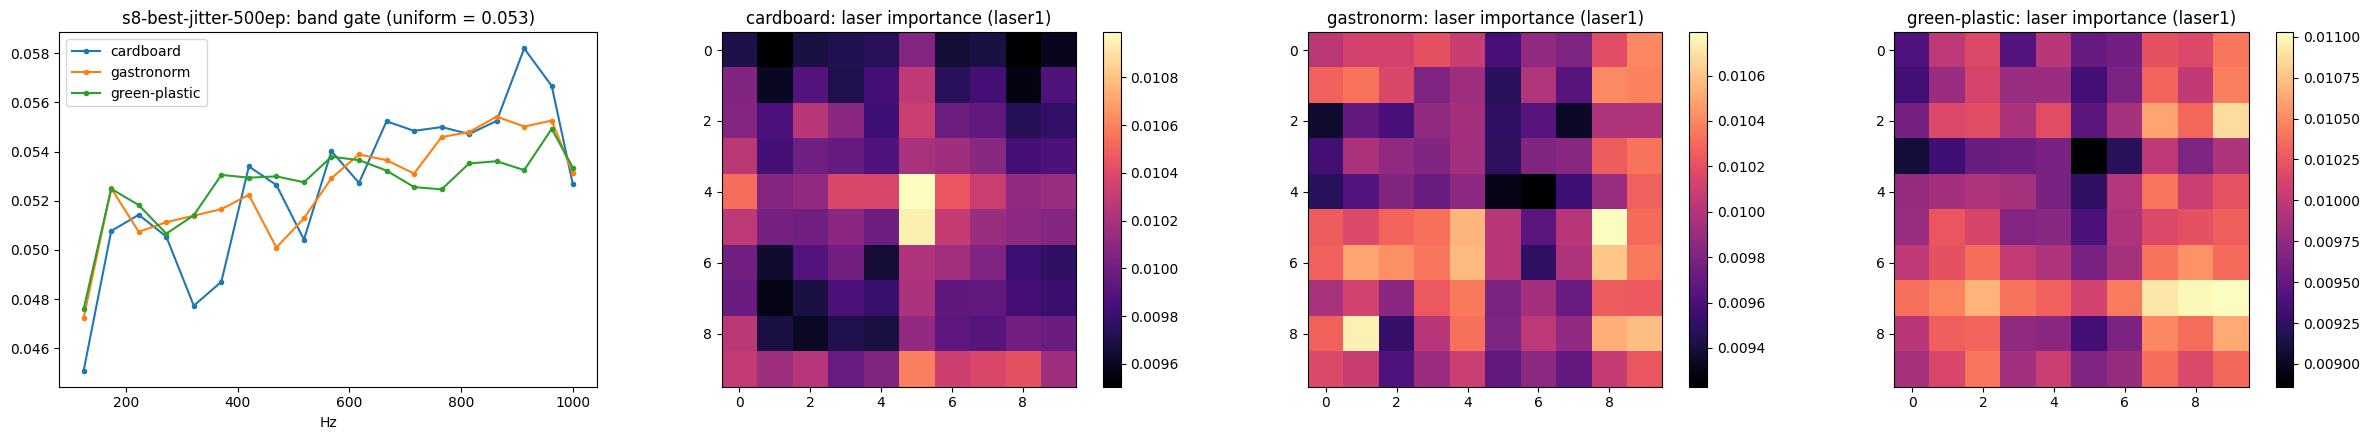

s8-best-jitter-500ep geo alpha per layer x head: [[ 0.1   0.67  4.48 30.  ]
 [ 0.1   0.67  4.48 30.  ]]


collecting 2026_09_27_gastronorm_four_objs:   0%|          | 0/6155 [00:00<?, ?it/s]

collecting 2026_09_27_gastronorm_four_objs:  14%|█▍        | 856/6155 [00:00<00:00, 8556.99it/s]

collecting 2026_09_27_gastronorm_four_objs:  28%|██▊       | 1712/6155 [00:00<00:01, 2794.37it/s]

collecting 2026_09_27_gastronorm_four_objs:  42%|████▏     | 2567/6155 [00:00<00:00, 4032.74it/s]

...

collecting 2026_10_11_cardboard_four_objs:  75%|███████▌  | 5423/7228 [00:02<00:00, 2634.36it/s]

collecting 2026_10_11_cardboard_four_objs:  87%|████████▋ | 6285/7228 [00:02<00:00, 3417.42it/s]

collecting 2026_10_11_cardboard_four_objs:  99%|█████████▊| 7133/7228 [00:02<00:00, 4214.46it/s]

collecting 2026_10_11_cardboard_four_objs: 100%|██████████| 7228/7228 [00:02<00:00, 3040.45it/s]

2026_10_11_cardboard_four_objs: 7228 samples, skipped 0 incomplete: []


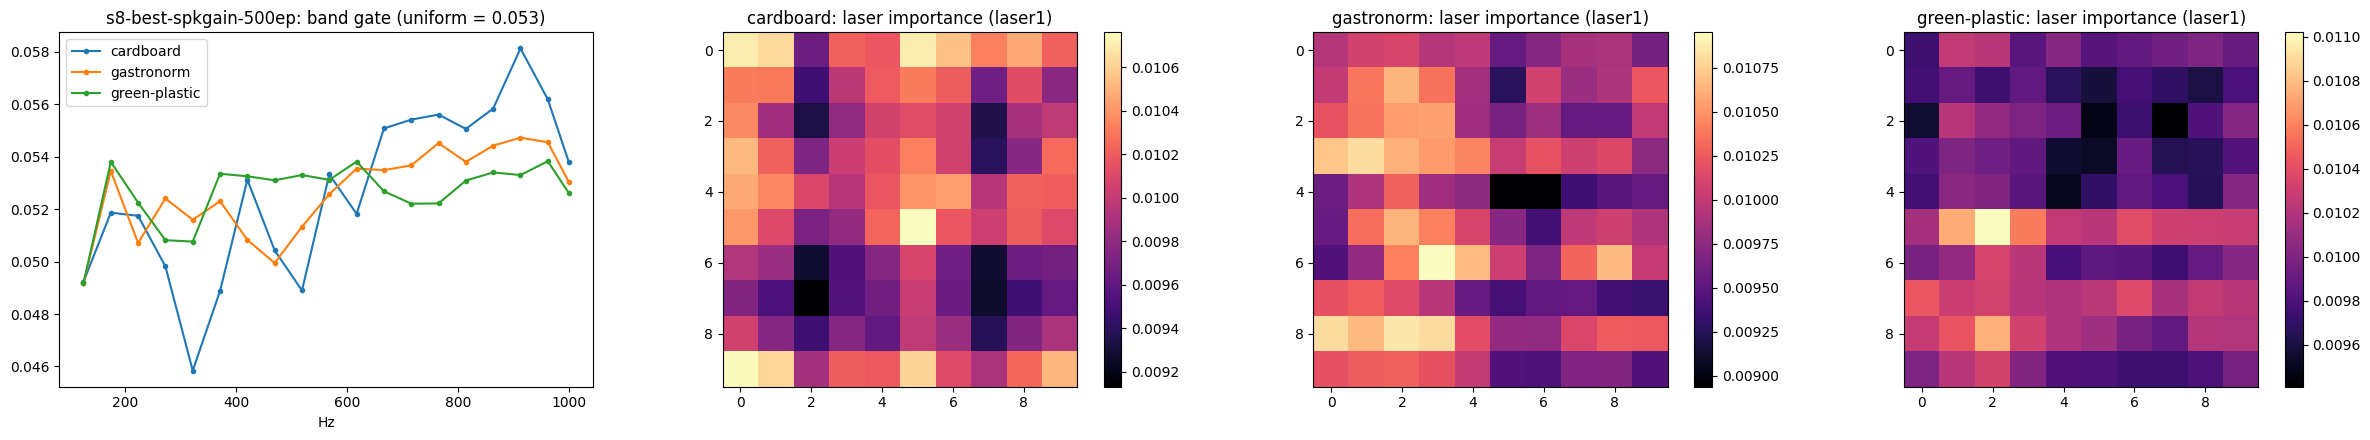

s8-best-spkgain-500ep geo alpha per layer x head: [[ 0.1   0.67  4.48 30.  ]
 [ 0.1   0.67  4.48 30.  ]]


collecting 2026_09_27_gastronorm_four_objs:   0%|          | 0/6155 [00:00<?, ?it/s]

collecting 2026_09_27_gastronorm_four_objs:  14%|█▍        | 861/6155 [00:00<00:00, 8608.76it/s]

collecting 2026_09_27_gastronorm_four_objs:  28%|██▊       | 1732/6155 [00:00<00:00, 8664.53it/s]

collecting 2026_09_27_gastronorm_four_objs:  42%|████▏     | 2599/6155 [00:00<00:01, 3219.49it/s]

...

collecting 2026_10_11_cardboard_four_objs:  71%|███████   | 5102/7228 [00:01<00:00, 5301.61it/s]

collecting 2026_10_11_cardboard_four_objs:  82%|████████▏ | 5958/7228 [00:01<00:00, 6056.77it/s]

collecting 2026_10_11_cardboard_four_objs:  94%|█████████▎| 6770/7228 [00:02<00:00, 2079.56it/s]

collecting 2026_10_11_cardboard_four_objs: 100%|██████████| 7228/7228 [00:02<00:00, 2931.44it/s]

2026_10_11_cardboard_four_objs: 7228 samples, skipped 0 incomplete: []


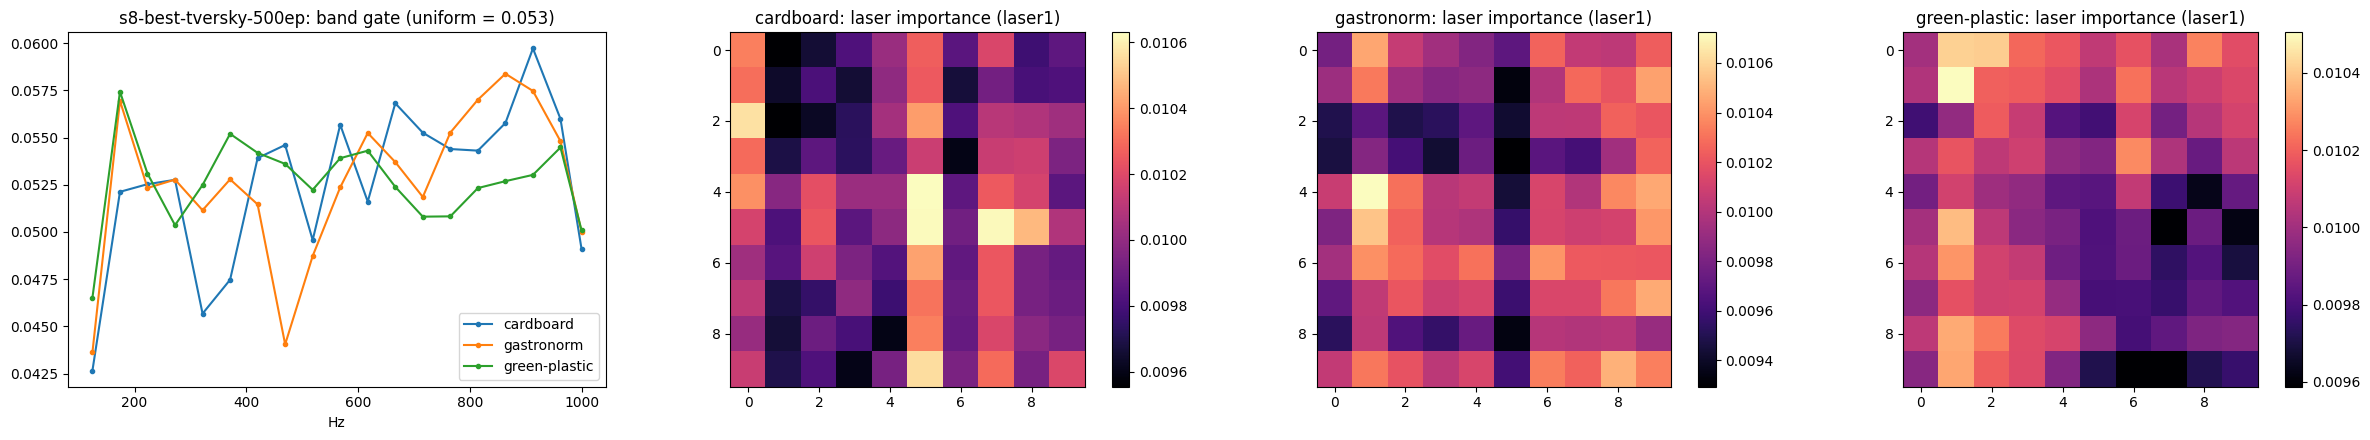

s8-best-tversky-500ep geo alpha per layer x head: [[ 0.1   0.67  4.48 30.  ]
 [ 0.1   0.67  4.48 30.  ]]


collecting 2026_09_27_gastronorm_four_objs:   0%|          | 0/6155 [00:00<?, ?it/s]

collecting 2026_09_27_gastronorm_four_objs:  14%|█▍        | 858/6155 [00:00<00:00, 8578.52it/s]

collecting 2026_09_27_gastronorm_four_objs:  28%|██▊       | 1724/6155 [00:00<00:00, 8621.65it/s]

collecting 2026_09_27_gastronorm_four_objs:  42%|████▏     | 2588/6155 [00:00<00:00, 8628.99it/s]

...

collecting 2026_10_11_cardboard_four_objs:  71%|███████   | 5137/7228 [00:01<00:00, 3659.12it/s]

collecting 2026_10_11_cardboard_four_objs:  83%|████████▎ | 5989/7228 [00:01<00:00, 4494.88it/s]

collecting 2026_10_11_cardboard_four_objs:  95%|█████████▍| 6844/7228 [00:01<00:00, 5294.47it/s]

collecting 2026_10_11_cardboard_four_objs: 100%|██████████| 7228/7228 [00:01<00:00, 4384.65it/s]

2026_10_11_cardboard_four_objs: 7228 samples, skipped 0 incomplete: []


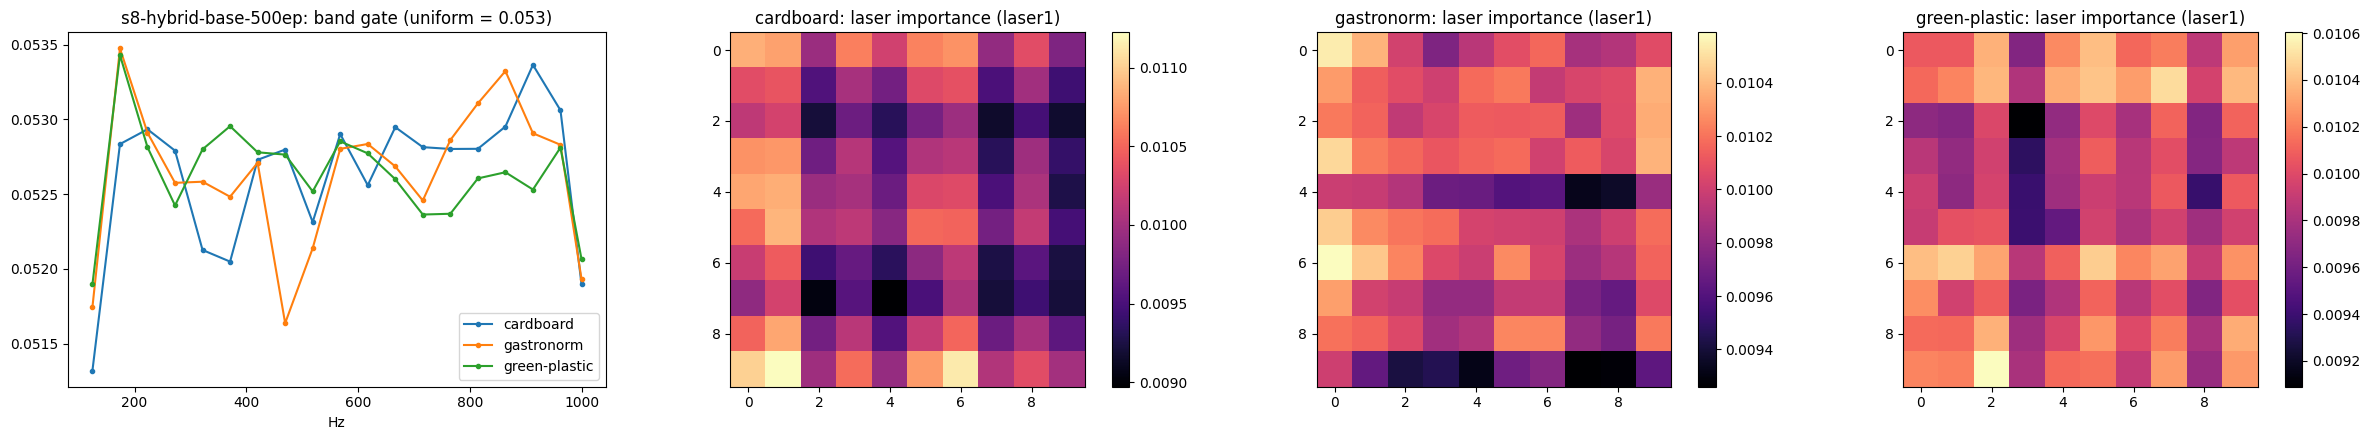

s8-hybrid-base-500ep geo alpha per layer x head: [[ 0.1   0.67  4.48 30.  ]
 [ 0.1   0.67  4.48 30.  ]]


In [10]:
from probe import eval_data, load_model, box_index, run_args
def explain(run, n=200):
    a = run_args(run)
    X, y, labels, info = eval_data("gastronorm_plastic_cardboard", a.signal, a.window, laser_center=bool(a.laser_center))
    ck = sorted((ROOT / "runs" / run / "checkpoints").glob("ep*-rank0.pt"), key=lambda p: int(p.name[2:].split("-")[0]))[-1]
    m = load_model("src8", run, ck, info, {})
    box = box_index(labels, info)
    sel = torch.linspace(0, len(X) - 1, n).long()
    with torch.no_grad(), torch.autocast("cuda", torch.bfloat16):
        o = m.forward_modal(X[sel].cuda().float(), {"box": box[sel].cuda()}, explain=True)["maps"]
    return o, box[sel].numpy(), m, info
MODAL = [r for r in RUNS if r.startswith("s8-") and run_args(r) is not None and run_args(r).encoder == "modal" and (ROOT / "runs" / r / "checkpoints").exists()]
for r in MODAL[:4]:
    o, bx, m, info = explain(r)
    hz = 10 ** (m.modal.band_logf.cpu().numpy() + 2.5)
    fig, axs = plt.subplots(1, 4, figsize=(24, 4.5))
    for b, name in enumerate(info["boxes"]):
        axs[0].plot(hz, o["band_pool"][bx == b].float().mean((0, 1, 2)).cpu(), "-o", ms=3, label=name)
    axs[0].set_xlabel("Hz"); axs[0].set_title(f"{r}: band gate (uniform = {1 / len(hz):.3f})"); axs[0].legend()
    key = sorted(k for k in o if k.startswith("cross")) or sorted(k for k in o if k.startswith("laser"))
    for b, name in enumerate(info["boxes"]):
        w = o[key[-1]][torch.tensor(bx == b)].float().mean((0, 1, 2)).cpu().view(10, 10) if key else torch.zeros(10, 10)
        im = axs[b + 1].imshow(w, cmap="magma"); axs[b + 1].set_title(f"{name}: laser importance ({key[-1] if key else '-'})"); plt.colorbar(im, ax=axs[b + 1])
    plt.tight_layout(); plt.show()
    if m.modal.geo: print(r, "geo alpha per layer x head:", torch.nn.functional.softplus(m.modal.geo_alpha).detach().cpu().numpy().round(2))

## 8b Faithful importance: occlusion (`src8/attribution.py`)

The gates and attention above are near uniform (within ±1.5% and ±10%), and a following linear layer can rescale anything, so they are not importance. Instead: replace one ~49 Hz band, or one laser, with its box's mean signal and measure the iou@0.08 drop on the CORE + HARD samples.

- cardboard needs the high end (600–960 Hz), plastic the low end (125–270 Hz).
- The hybrid reads more of the spectrum than conv in cardboard and gastro.
- No single laser matters much: the information is spread redundantly over the grid.

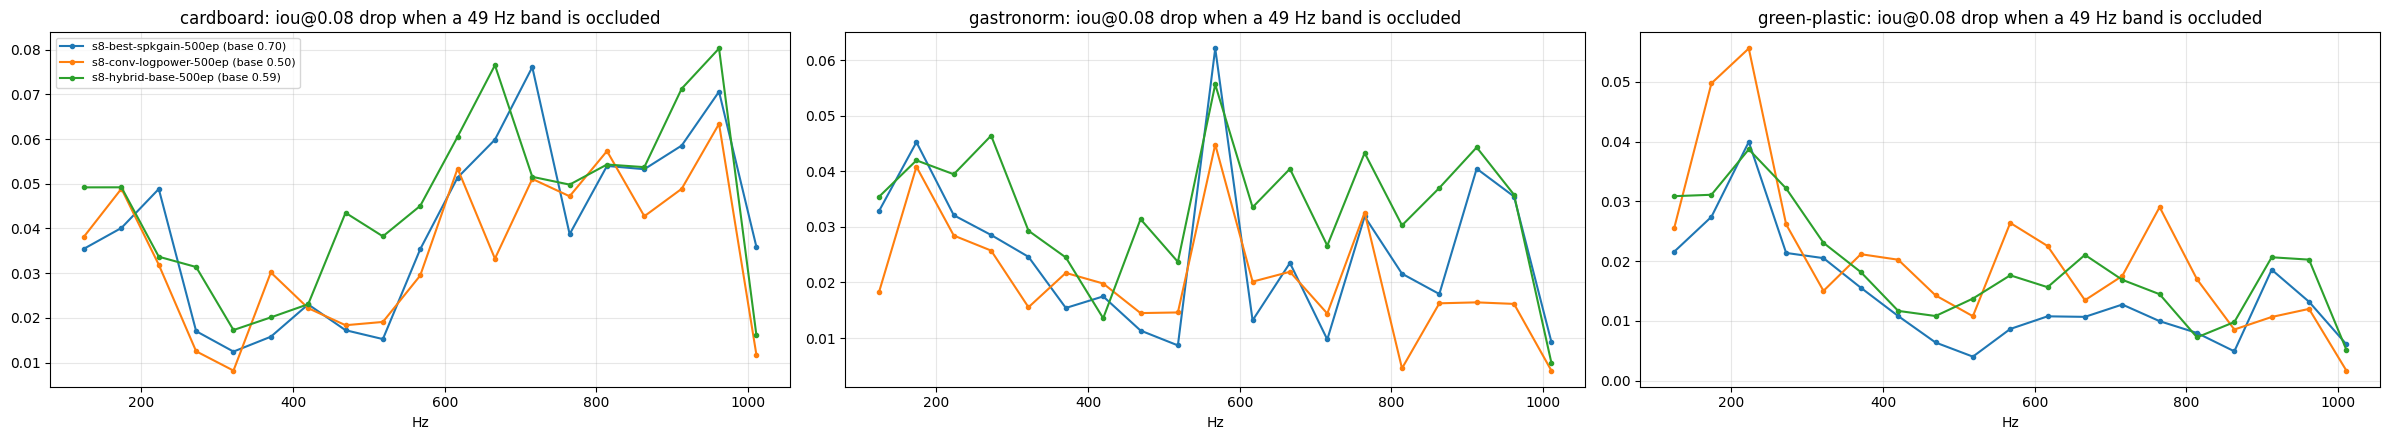

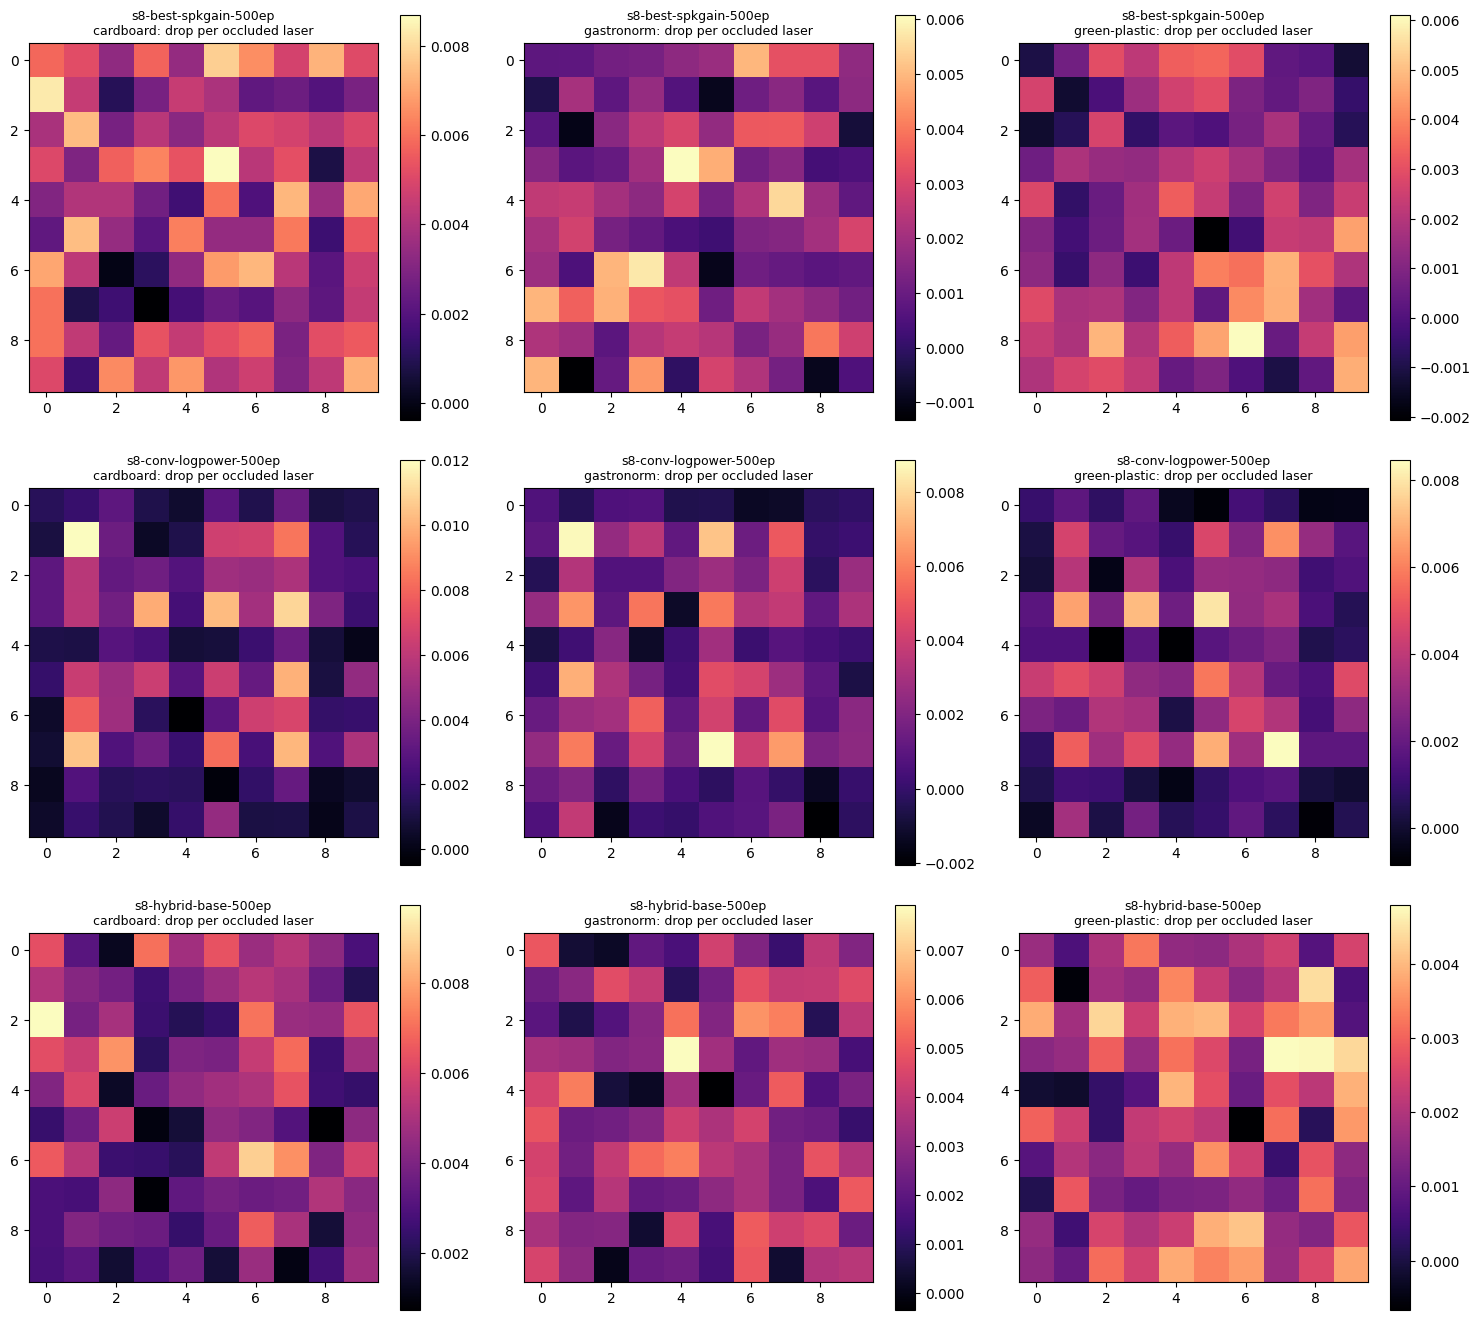

In [11]:
att = {r: torch.load(ROOT / "runs" / r / "attribution.pt") for r in RUNS if (ROOT / "runs" / r / "attribution.pt").exists()}
fig, axs = plt.subplots(1, 3, figsize=(24, 4.5))
for r, a in att.items():
    for b, name in enumerate(a["boxes"]):
        axs[b].plot(a["hz"], a["band"][b], "-o", ms=3, label=f"{r} (base {a['base'][b]:.2f})")
        axs[b].set_title(f"{name}: iou@0.08 drop when a 49 Hz band is occluded"); axs[b].set_xlabel("Hz"); axs[b].grid(alpha=.3)
axs[0].legend(fontsize=8); plt.tight_layout(); plt.show()
fig, axs = plt.subplots(len(att), 3, figsize=(15, 4.5 * len(att)), squeeze=False)
for i, (r, a) in enumerate(att.items()):
    for b, name in enumerate(a["boxes"]):
        im = axs[i, b].imshow(a["laser"][b].view(10, 10), cmap="magma"); axs[i, b].set_title(f"{r}\n{name}: drop per occluded laser", fontsize=9); plt.colorbar(im, ax=axs[i, b])
plt.tight_layout(); plt.show()

## 9 Conclusions (2026-10-19; later queue arms are added to the tables above as they finish)

**Best model: `s8-best-spkgain-500ep`, which beats the target on every headline number.**

| | CORE iou / miss | HARD iou / miss / orient | ALL iou / miss | unseen speaker | unseen laser |
|---|---|---|---|---|---|
| target `s7-gpc-tukey-logpower-1k` @500 | .580 / .043 | .420 / .024 / 36° | .300 / .272 | .260 | .110 |
| **s8-best-spkgain** @500 | **.722 / .006** | **.596 / .000 / 18°** | **.388 / .168** | **.275** | **.201** |

**The recipe.** Each step was added to fix a failure diagnosed in the previous run:
1. **The hybrid ModalFormer front end** (+.06 CORE over the 500-ep conv control).
   - A conv frequency stem, then 19 band tokens of ~49 Hz per laser, gated flatten pooling over bands, attention over the 100 lasers with learned laser / band / box embeddings, and a per-box input norm, feeding the conv mask decoder.
   - The conv decoder kept *exact peak positions* (Rayleigh: the added mass shifts each mode by ∝ m φ²) and *laser identity*. Mean-pooling over bands or lasers (v1) erased both and fit a constant mask.
2. **The pose-factored STN branch** (rotated soap 30° → 21°, HARD .518 → .550).
   - A canonical mask is warped by an angle head (doubled-angle, supervised) and centred at the soft-argmax of the direct mask, then merged as a *residual*: the soft-OR version could only add pixels and over-painted.
3. **Outline channel + moment loss** (area / centroid / covariance): CORE .662 → .689, orientation 17.6°.
4. **Laser jitter** (the grid resampled at ±0.5-cell sub-cell shifts): unseen laser .113 → .170, HARD .603 with 0 misses.
5. **Speaker gain** (a random log-gain shared by all lasers, smooth on the ~20 Hz scale of measured speaker differences): unseen speaker .228 → .275. It also recovered the two-object scenes that jitter had hurt.

**What didn't work:**
- v1's pixel-query ModalFormer (constant mask).
- The soft-OR pose merge.
- The com head as the pose centre (2× worse than the mask centroid).
- AdaBN / TENT-style test-time stats: single-object domains, so the domain mean *is* the object.
- The old low-order colour augmentation.
- Center / empty-box / deconvolution preprocessing: no gain in the training-free probe.
- Tversky loss: within noise.

**Interpretability** (§8b, occlusion, not attention):
- Information is box-specific. Cardboard reads 650–960 Hz (its low modes are damped away), green plastic 125–270 Hz, and gastronorm both ranges.
- No single laser matters (max .009 iou each): the information is spread over the wall's redundant lasers.
- The in-architecture gates and attention are near uniform, so they are *not* importance.

**Remaining failures:**
- Light cylinders and lids (physics limit: too little added mass).
- Gastro speaker 4 (.125).
- Large laser shifts (cardboard shifted-3/-4 ≤ .09).
- Two-cube scenes (.22–.29; cube + vase .36–.44).
- Cardboard random-pose cube (.43).
